# Fase 4 — Inferencia causal, Causal ML y el choque predictivo vs causal
**Responsable:** Julián Agustín Lozano (Backend & ML / Causal) · **Borrador para integrar al notebook maestro (secciones 4 y 5).**

**Pregunta causal:** ¿qué efecto tiene **usar cupones** ($T$ = `coupon_any` $= \mathbb{1}\{\text{CouponUsed} \ge 1\}$) sobre la probabilidad de **churn** ($Y$), una vez bloqueada la autoselección por las características del cliente ($Z$)?

**Marco de resultados potenciales.** Cada cliente tiene dos resultados potenciales, $Y_i(1)$ y $Y_i(0)$, y observamos solo uno. El estimando es
$$\text{ATE} = \tau = \mathbb{E}[Y(1) - Y(0)] = P(\text{Churn}=1 \mid do(T=1)) - P(\text{Churn}=1 \mid do(T=0)).$$
Un $\tau < 0$ significa que el cupón **retiene**. Unidad: puntos porcentuales (pp) de probabilidad de churn.

**Supuestos de identificación:**
1. **SUTVA:** el resultado de un cliente no depende del tratamiento de otros, y hay una sola versión del tratamiento.
2. **Ignorabilidad condicional:** $\{Y(1), Y(0)\} \perp T \mid Z$, es decir, no hay confusores fuera de $Z$ (supuesto no testeable).
3. **Positividad:** $0 < P(T=1 \mid Z=z) < 1$ para todo $z$ relevante (sí es testeable, sección 4.3).

Bajo 1-3, el criterio backdoor da $P(Y \mid do(T=t)) = \sum_z P(Y \mid T=t, Z=z)\,P(Z=z)$.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "borradores" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src import causal
from src import preprocessing as prep

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

df = prep.make_clean_dataset()
r = causal.run_causal_analysis(df)   # ~1,5 min: DoWhy, refutaciones (100 sim.) y EconML
p = causal.results_payload(r)
pp = lambda x: f"{x * 100:+.2f} pp"
print(f"Clientes: {p['n']['n_total']} | con T observado: {p['n']['support']['n_antes']} | "
      f"con soporte común: {p['n']['support']['n_soporte']}")

Clientes: 2982 | con T observado: 2849 | con soporte común: 2012


## 4.1 DAG estructural
Roles (contrato de datos confirmado por el Project Lead; justificación arco por arco en la Bitácora, Entrada 4.1):
- **Z (confusores, pre-tratamiento):** antigüedad, reclamos, satisfacción, segmento geográfico y de categoría, uso de la app, medios de pago, dispositivo, demografía y logística. Cada $Z \to T$ y $Z \to Y$.
- **M (mediadores):** `OrderCount` y `CashbackAmount`. El cupón induce más pedidos y más cashback, que a su vez retienen: $T \to M \to Y$.
- **C (colisionador):** `DaySinceLastOrder`. El cupón acorta los días desde la última compra y el churn los alarga: $T \to C \leftarrow Y$.
- **U (latente, no observado):** `U_engagement`, la afinidad con la marca. Afecta el uso de la app, el uso de cupones y el churn.

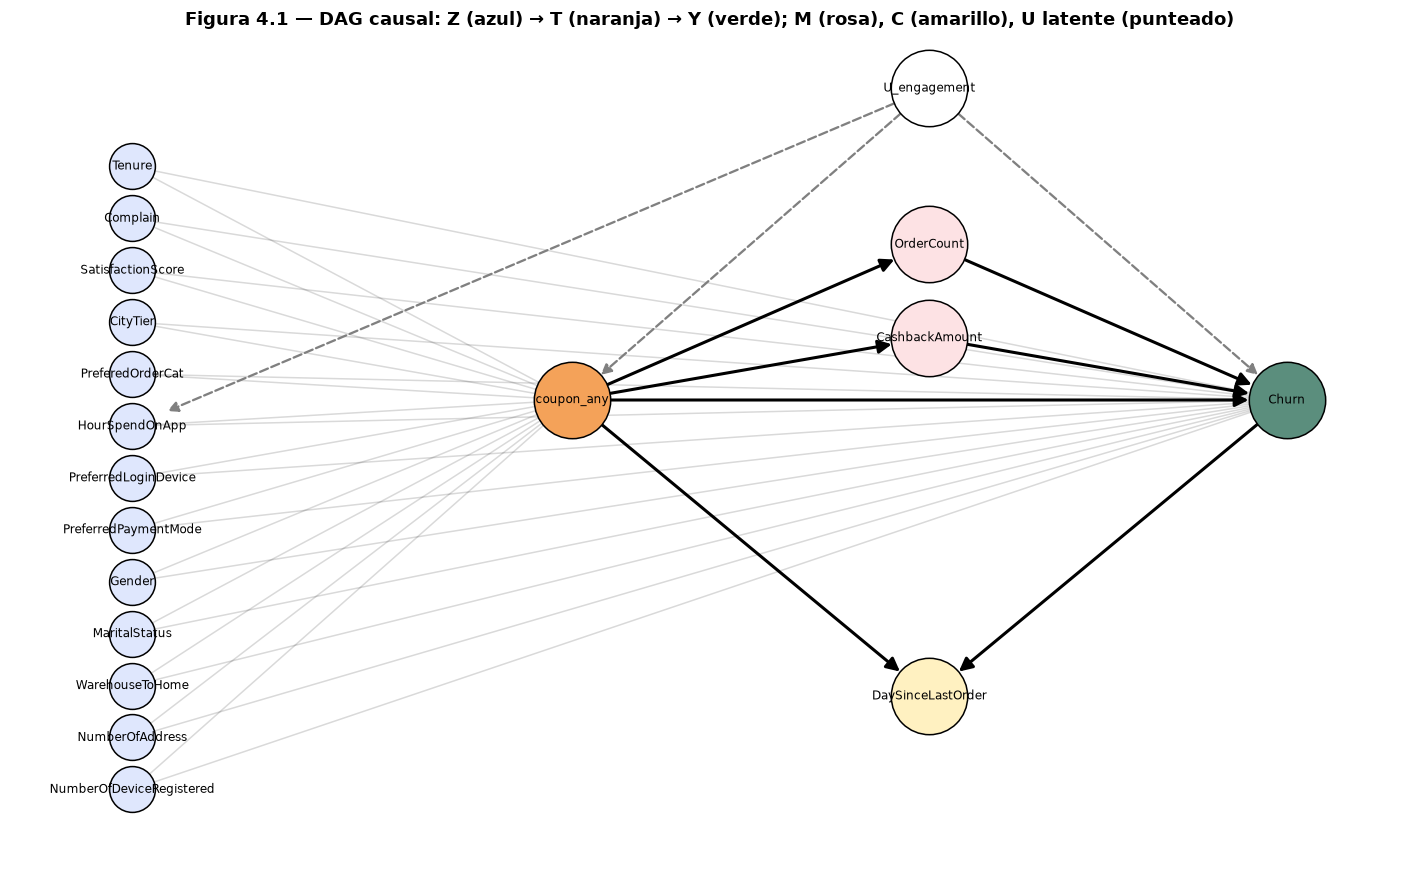

In [2]:
g = r["dag"]
roles = dict(g.nodes(data="role"))
zs = [n for n in g if roles[n] == "Z"]
pos = {n: (0, 1 - i / (len(zs) - 1) * 2) for i, n in enumerate(zs)}
pos.update({causal.TREATMENT: (1.6, 0.25), causal.OUTCOME: (4.2, 0.25), causal.LATENT: (2.9, 1.25),
            "OrderCount": (2.9, 0.75), "CashbackAmount": (2.9, 0.45), "DaySinceLastOrder": (2.9, -0.7)})
colors = {"Z": "#dfe7fd", "T": "#f4a259", "Y": "#5b8e7d", "M": "#fde2e4", "C": "#fff1c1", "U": "white"}
fig, ax = plt.subplots(figsize=(13, 8))
z_edges = [(a, b) for a, b in g.edges if roles[a] == "Z"]
other = [(a, b) for a, b in g.edges if roles[a] not in ("Z", "U")]
nx.draw_networkx_edges(g, pos, edgelist=z_edges, alpha=0.15, arrowsize=8, ax=ax)
nx.draw_networkx_edges(g, pos, edgelist=other, width=2, arrowsize=18, ax=ax, node_size=2500)
nx.draw_networkx_edges(g, pos, edgelist=list(g.out_edges(causal.LATENT)), style="dashed", width=1.5,
                       edge_color="gray", arrowsize=14, ax=ax, node_size=2500)
for role, color in colors.items():
    nodes = [n for n in g if roles[n] == role]
    nx.draw_networkx_nodes(g, pos, nodelist=nodes, node_color=color, edgecolors="black",
                           node_size=900 if role == "Z" else 2500, ax=ax)
nx.draw_networkx_labels(g, pos, font_size=8, ax=ax)
ax.set_title("Figura 4.1 — DAG causal: Z (azul) → T (naranja) → Y (verde); M (rosa), C (amarillo), U latente (punteado)")
ax.axis("off")
plt.tight_layout()
plt.show()

## 4.2 Identificación: criterio backdoor
Un conjunto $S$ cumple el criterio backdoor respecto de $(T, Y)$ si **(i)** ningún nodo de $S$ es descendiente de $T$, y **(ii)** $S$ bloquea todo camino entre $T$ e $Y$ que entra a $T$ por una flecha ($T \leftarrow \cdots$).

**Demostración para $S = Z$:** en este DAG todos los caminos backdoor tienen la forma $T \leftarrow Z_j \rightarrow Y$, una bifurcación. Condicionar en el nodo central $Z_j$ la bloquea. Ningún $Z_j$ desciende de $T$, porque son pre-tratamiento. Por lo tanto $Z$ satisface (i) y (ii). Se verifica abajo por d-separación (`networkx`) en el grafo sin las aristas salientes de $T$.

**Las trampas:**
- **Mediador** ($S = Z \cup M$): viola (i). Condicionar en $M$ bloquea $T \to M \to Y$ y se estima solo el efecto **directo**, subestimando el efecto total de la política.
- **Colisionador** ($S = Z \cup C$): viola (i). Condicionar en $C$ **abre** el camino $T \to C \leftarrow Y$ y crea una asociación espuria entre $T$ e $Y$ (sesgo de Berkson).
- **Latente** $U$: el camino $T \leftarrow U \to Y$ no puede bloquearse. Si $U$ existe, el efecto **no está identificado**, de ahí el análisis de sensibilidad (sección 4.6).

In [3]:
bd = p["backdoor"]
rows = [("Z (13 confusores), sin U", bd["sin_latente"]), ("Z, con U en el DAG", bd["con_latente"]),
        ("Z + M (mediadores)", bd["Z+M"]), ("Z + C (colisionador)", bd["Z+C"])]
print("Tabla 4.1 — Verificación del criterio backdoor por d-separación")
display(pd.DataFrame([{"conjunto": n, "(i) sin descendientes de T": b["no_descendants_of_T"],
                       "(ii) bloquea backdoor": b["blocks_all_backdoor_paths"], "cumple": b["satisfied"],
                       "descendientes incluidos": ", ".join(b["descendants_in_set"]) or "—"} for n, b in rows]))
print(f"Caminos backdoor (sin U): {len(bd['caminos'])}, por ejemplo: {bd['caminos'][:3]}")
print(f"DoWhy identifica un set de {len(p['dowhy_backdoor_set'])} columnas codificadas; "
      f"¿incluye M o C? {bool(set(p['dowhy_backdoor_set']) & set(prep.MEDIATORS + prep.COLLIDERS))}")

Tabla 4.1 — Verificación del criterio backdoor por d-separación


,conjunto,(i) sin descendientes de T,(ii) bloquea backdoor,cumple,descendientes incluidos
0,"Z (13 confusores), sin U",True,True,True,—
1,"Z, con U en el DAG",True,False,False,—
2,Z + M (mediadores),False,False,False,"CashbackAmount, OrderCount"
3,Z + C (colisionador),False,False,False,DaySinceLastOrder


Caminos backdoor (sin U): 13, por ejemplo: ['coupon_any - Tenure - Churn', 'coupon_any - Complain - Churn', 'coupon_any - SatisfactionScore - Churn']
DoWhy identifica un set de 29 columnas codificadas; ¿incluye M o C? False


In [4]:
print(r["estimand"])

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                                                                        ↪
─────────────(E[Churn|NumberOfDeviceRegistered_5,HourSpendOnApp_3,NumberOfDevi ↪
d[coupon_any]                                                                  ↪

↪                                                                              ↪
↪ ceRegistered_2,na_WarehouseToHome,PreferedOrderCat_Others,SatisfactionScore, ↪
↪                                                                              ↪

↪                                                                              ↪
↪ CityTier_3,WarehouseToHome,Tenure,PreferedOrderCat_Mobile_Phone,HourSpendOnA ↪
↪                                                                              ↪

↪                                                                              ↪
↪ pp_1,na_HourSpendOnApp,NumberOfDeviceRegistered_3,PreferedOrderCat_Laptop_an

## 4.3 Positividad y soporte común
La positividad exige que, para cada perfil $z$, haya clientes con y sin cupón. En este dataset hay **estratos enteros donde el 100% usó cupón**: ahí no existe contrafáctico observable, y cualquier estimación sería pura extrapolación del modelo. Se procede en dos pasos:
1. Se excluyen los estratos con ≥ 20 clientes y sin variación en $T$.
2. Se recortan los clientes con propensity $\hat e(z) = P(T=1 \mid Z=z)$ fuera de $[0{,}05;\ 0{,}95]$.

El ATE resultante es el de la **población con soporte común**, y así se informa.

Tabla 4.2 — Estratos sin contrafáctico (todos tratados)


,variable,nivel,n,share_tratados
0,Tenure,31.0,23,1.0
1,HourSpendOnApp,4.0,605,1.0
2,WarehouseToHome,36.0,25,1.0
3,WarehouseToHome,7.0,202,1.0
4,NumberOfAddress,11,49,1.0
5,NumberOfDeviceRegistered,6,87,1.0


Excluidos por estratos: 808 | por trimming: 29 | población final: 2012


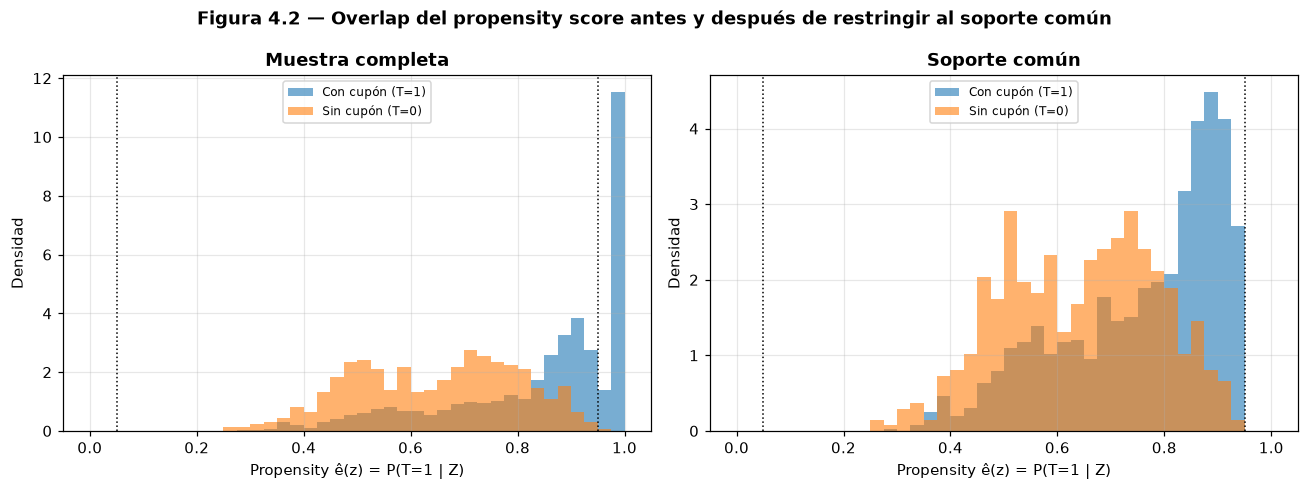

Fuera de [0,05; 0,95] en la muestra completa: 26.1%


In [5]:
s = p["n"]["support"]
print("Tabla 4.2 — Estratos sin contrafáctico (todos tratados)")
display(pd.DataFrame(s["estratos_excluidos"]))
print(f"Excluidos por estratos: {s['n_excluidos_estratos']} | por trimming: {s['n_excluidos_trimming']} | "
      f"población final: {s['n_soporte']}")

frame_full, info_full = causal.prepare_causal_frame(df)
ps_full = causal.propensity_scores(frame_full, info_full["z_cols"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, (title, f, ps) in zip(axes, [("Muestra completa", frame_full, ps_full),
                                      ("Soporte común", r["frame"], r["propensity"])]):
    t = f[causal.TREATMENT].to_numpy()
    bins = np.linspace(0, 1, 41)
    ax.hist(ps[t == 1], bins=bins, alpha=0.6, density=True, label="Con cupón (T=1)")
    ax.hist(ps[t == 0], bins=bins, alpha=0.6, density=True, label="Sin cupón (T=0)")
    for b in causal.PS_BOUNDS:
        ax.axvline(b, color="k", ls=":", lw=1)
    ax.set(title=title, xlabel="Propensity ê(z) = P(T=1 | Z)", ylabel="Densidad")
    ax.legend(fontsize=8)
fig.suptitle("Figura 4.2 — Overlap del propensity score antes y después de restringir al soporte común", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Fuera de [0,05; 0,95] en la muestra completa: {p['overlap_full_sample']['share_outside_05_95']:.1%}")

**Balance de covariables.** La diferencia de medias estandarizada, $\text{SMD}_j = (\bar z_{j,1} - \bar z_{j,0}) / \sqrt{(s^2_{j,1} + s^2_{j,0})/2}$, se calcula antes y después de ponderar por IPW ($w_i = T_i/\hat e_i + (1-T_i)/(1-\hat e_i)$). Criterio usual: $|\text{SMD}| < 0{,}1$.

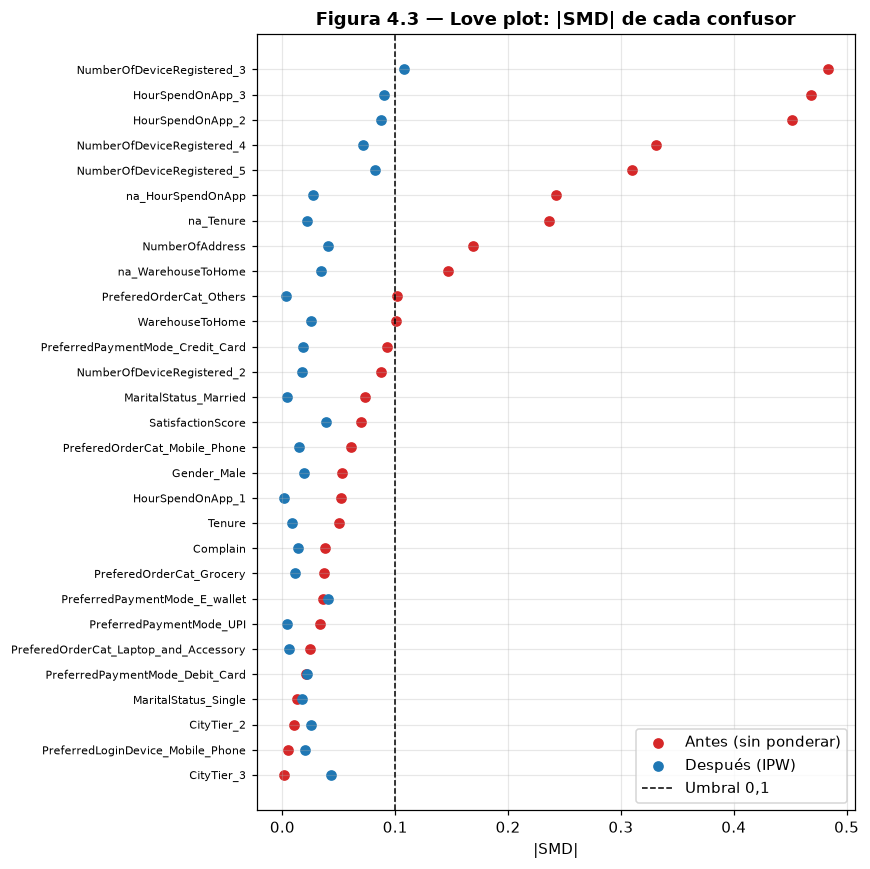

max |SMD|: 0.483 → 0.107; variables con |SMD| > 0,1: 11 → 1


In [6]:
bal = r["balance"]
order = bal.smd_antes.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(bal.loc[order, "smd_antes"].abs(), order, label="Antes (sin ponderar)", color="tab:red")
ax.scatter(bal.loc[order, "smd_despues"].abs(), order, label="Después (IPW)", color="tab:blue")
ax.axvline(0.1, color="k", ls="--", lw=1, label="Umbral 0,1")
ax.set(title="Figura 4.3 — Love plot: |SMD| de cada confusor", xlabel="|SMD|")
ax.tick_params(axis="y", labelsize=7)
ax.legend()
plt.tight_layout()
plt.show()
print(f"max |SMD|: {p['balance']['max_abs_smd_antes']:.3f} → {p['balance']['max_abs_smd_despues']:.3f}; "
      f"variables con |SMD| > 0,1: {p['balance']['n_smd_mayor_0_1_antes']} → {p['balance']['n_smd_mayor_0_1_despues']}")

## 4.4 Estimación en 4 pasos con DoWhy y comparación con el estimador ingenuo
1. **Model:** `CausalModel(data, treatment, outcome, graph)` con el DAG en las columnas codificadas.
2. **Identify:** `identify_effect()` devuelve el estimando backdoor de arriba.
3. **Estimate:**
   - `backdoor.linear_regression`: modelo de probabilidad lineal $Y = \alpha + \tau T + Z^\top\gamma + \varepsilon$; $\hat\tau$ es el ATE en pp.
   - `backdoor.propensity_score_weighting` (IPW): $\hat\tau = \frac{\sum_i T_i Y_i/\hat e_i}{\sum_i T_i/\hat e_i} - \frac{\sum_i (1-T_i) Y_i/(1-\hat e_i)}{\sum_i (1-T_i)/(1-\hat e_i)}$.
4. **Comparar** con la regresión ingenua $Y \sim T$. El **sesgo de confusión** es $\hat\tau_{\text{ingenuo}} - \hat\tau_{\text{ajustado}}$.

Se agregan los dos estimadores de EconML (sección 4.7) y las dos "trampas".

Tabla 4.3 — Estimaciones del efecto de usar cupón sobre la probabilidad de churn (pp)


,ATE (pp),IC 95% inf,IC 95% sup
Ingenuo (Y ~ T),-0.35,-4.15,3.45
Backdoor: regresión lineal,-1.16,-4.60,2.28
Backdoor: IPW,-1.09,-5.56,3.14
LinearDML (EconML),1.11,-2.03,4.24
CausalForestDML (EconML),1.42,-1.46,4.29
Con M (trampa del mediador),-2.39,-5.91,1.13
Con C (trampa del colisionador),-0.74,-4.15,2.68
Regresión en muestra completa (extrapola),-1.17,-4.55,2.21
T continua: por cupón adicional,1.07,0.14,2.00


Tasas de churn (ingenuo): con cupón 18.0% vs sin cupón 18.4%
Sesgo de confusión (ingenuo − regresión backdoor): +0.81 pp


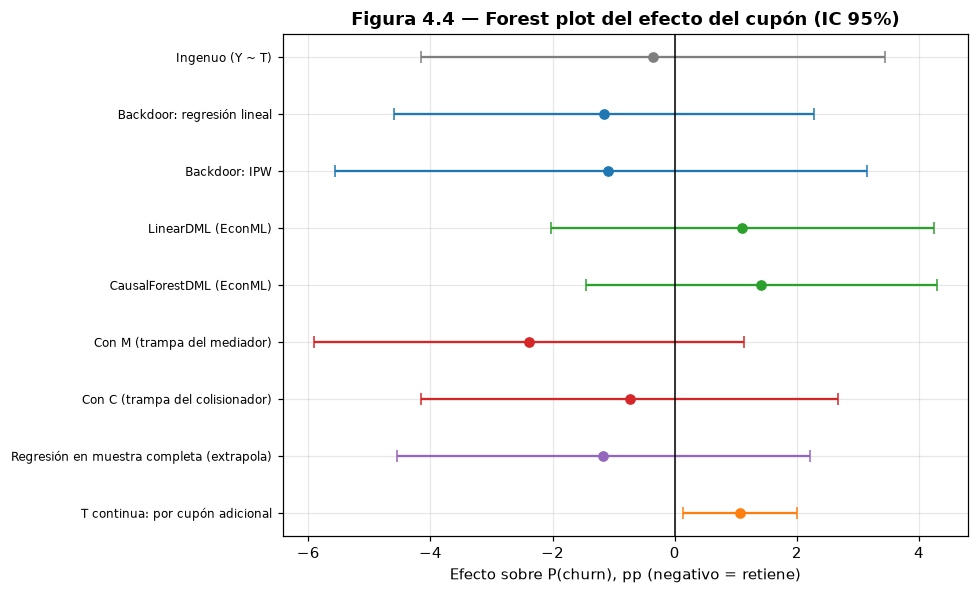

In [7]:
est = pd.DataFrame(p["estimates"]).T
est["ATE (pp)"] = est.ate * 100
est["IC 95% inf"] = est.ci.str[0] * 100
est["IC 95% sup"] = est.ci.str[1] * 100
est = est[["ATE (pp)", "IC 95% inf", "IC 95% sup"]].astype(float)
dr = p["dose_response_per_coupon"]
est.loc["T continua: por cupón adicional"] = [dr["ate"] * 100, dr["ci"][0] * 100, dr["ci"][1] * 100]
print("Tabla 4.3 — Estimaciones del efecto de usar cupón sobre la probabilidad de churn (pp)")
display(est.round(2))
print(f"Tasas de churn (ingenuo): con cupón {p['naive_churn_rates']['T=1']:.1%} vs sin cupón {p['naive_churn_rates']['T=0']:.1%}")
print(f"Sesgo de confusión (ingenuo − regresión backdoor): {pp(p['confounding_bias'])}")

colors = ["tab:gray", "tab:blue", "tab:blue", "tab:green", "tab:green", "tab:red", "tab:red", "tab:purple", "tab:orange"]
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(est))[::-1]
for yi, (_, row), color in zip(y, est.iterrows(), colors):
    ax.errorbar(row["ATE (pp)"], yi, xerr=[[row["ATE (pp)"] - row["IC 95% inf"]], [row["IC 95% sup"] - row["ATE (pp)"]]],
                fmt="o", color=color, capsize=4)
ax.axvline(0, color="k", lw=1)
ax.set_yticks(y, est.index, fontsize=8)
ax.set(title="Figura 4.4 — Forest plot del efecto del cupón (IC 95%)", xlabel="Efecto sobre P(churn), pp (negativo = retiene)")
plt.tight_layout()
plt.show()

In [8]:
sim = p["collider_simulation"]
print("Tabla 4.4 — Simulación del sesgo de colisionador (efecto verdadero conocido, n = 20.000)")
pd.DataFrame({"estimación": [sim["true_effect"], sim["estimate_without_C"], sim["estimate_with_C"]]},
             index=["efecto verdadero", "Y ~ T (correcto)", "Y ~ T + C (condiciona en el colisionador)"]).round(3)

Tabla 4.4 — Simulación del sesgo de colisionador (efecto verdadero conocido, n = 20.000)


,estimación
efecto verdadero,0.100
Y ~ T (correcto),0.100
Y ~ T + C (condiciona en el colisionador),-0.463


**Lectura:**
- El ATE ajustado es **≈ 0** con todos los estimadores; todos los IC 95% incluyen 0.
- El sesgo de confusión es chico (+0,8 pp) porque los confusores observados casi no predicen el uso de cupón: por ejemplo, la correlación `Complain`–T es −0,02.
- Las trampas mueven la estimación en la dirección que predice la teoría, aunque sin significancia en estos datos:
  - Con M, −2,4 pp, el efecto "directo" una vez bloqueado el canal de pedidos y cashback.
  - Con C, −0,7 pp.
  - En la simulación con efecto conocido, condicionar en el colisionador cambia incluso el **signo**: +0,10 → −0,46.
- **Dosis-respuesta:** cada cupón adicional se asocia con +1,07 pp de churn (IC [+0,14; +2,00]), ajustando por Z. Lo más plausible es causalidad inversa o confusión no observada (por ejemplo, clientes "cazadores de ofertas" con baja lealtad), más que un efecto dañino del cupón.

## 4.5 Refutaciones (DoWhy) y semáforo
| Refutador | Qué hace | Expectativa |
|---|---|---|
| Random Common Cause | agrega un confusor aleatorio independiente | el ATE no se mueve |
| Placebo Treatment | reemplaza $T$ por una permutación aleatoria | el ATE → 0 |
| Data Subset | re-estima en submuestras del 80% | el ATE queda dentro del IC original |

Cada uno se corre con 100 simulaciones.

In [9]:
icon = {"verde": "🟢", "amarillo": "🟡", "rojo": "🔴"}
refs = pd.DataFrame(p["refutations"])
refs["ATE original (pp)"] = refs.ate_original * 100
refs["ATE refutado (pp)"] = refs.ate_nuevo * 100
refs["semáforo"] = refs.semaforo.map(lambda c: f"{icon[c]} {c}")
print("Tabla 4.5 — Refutaciones del estimador principal (regresión backdoor)")
refs[["refutador", "ATE original (pp)", "ATE refutado (pp)", "p_value_dowhy", "semáforo", "interpretacion"]].round(3)

Tabla 4.5 — Refutaciones del estimador principal (regresión backdoor)


,refutador,ATE original (pp),ATE refutado (pp),p_value_dowhy,semáforo,interpretacion
0,Random Common Cause,-1.159,-1.160,0.90,🟢 verde,Agregar un confusor aleatorio no debería mover...
1,Placebo Treatment,-1.159,0.093,0.96,🟢 verde,Con T permutado al azar el efecto debe ser ≈ 0.
2,Data Subset (80%),-1.159,-0.985,0.88,🟢 verde,Re-estimar en submuestras del 80% debe dejar e...


## 4.6 Sensibilidad a un confusor no observado
El backdoor descansa en que no exista $U$ (sección 4.2). `add_unobserved_common_cause` simula un confusor con efectos de intensidad 0,01-0,10 sobre $T$ (cambiando el tratamiento de una fracción de clientes) y sobre $Y$ (lineal), y re-estima el ATE.

In [10]:
sens = p["sensitivity_unobserved"]
print(f"Con un confusor no observado de intensidad {sens['strengths']}, el ATE varía entre "
      f"{pp(sens['ate_min'])} y {pp(sens['ate_max'])} (estimación original: {pp(p['estimates']['Backdoor: regresión lineal']['ate'])}).")

Con un confusor no observado de intensidad [0.01, 0.05, 0.1], el ATE varía entre -1.75 pp y +6.17 pp (estimación original: -1.16 pp).


**Lectura:** un confusor de intensidad moderada alcanza para llevar el ATE a +6 pp. La conclusión "no hay evidencia de efecto protector" es robusta, pero **no** permite afirmar un efecto exactamente nulo: la confusión no observada (`U_engagement`, sensibilidad al precio) es la principal amenaza a la validez interna (Bitácora, Entrada 4.3).

## 4.7 Causal ML: Double Machine Learning y heterogeneidad (CATE)
Modelo parcialmente lineal con efecto heterogéneo:
$$Y = \theta(X)\,T + g(X, W) + \varepsilon, \qquad T = m(X, W) + \eta,$$
donde $X$ = modificadores de efecto interpretables (`Tenure`, `Complain`, `SatisfactionScore`) y $W$ = resto de los confusores.

**Ortogonalización (Neyman / Frisch-Waugh-Lovell):**
1. Se predicen $\hat g = \mathbb{E}[Y \mid X, W]$ y $\hat m = \mathbb{E}[T \mid X, W]$ con **Random Forest** (modelos *nuisance*), con **cross-fitting** de 5 folds: cada predicción se hace con modelos que no vieron esa observación.
2. Se residualiza: $\tilde Y = Y - \hat g$ y $\tilde T = T - \hat m$.
3. Se estima $\theta(X)$ regresando $\tilde Y$ sobre $\tilde T$ (LinearDML: $\theta$ lineal en $X$; CausalForestDML: $\theta$ no paramétrico).

Como la condición de momento es ortogonal, los errores de primer orden en $\hat g$ y $\hat m$ no sesgan $\hat\theta$.

**CATE:** $\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$.

In [11]:
coefs = pd.DataFrame(p["linear_dml_coefs"]).set_index("")
print("Tabla 4.6 — LinearDML: θ(X) = θ0 + X'β (efecto marginal de cada modificador sobre el CATE)")
display(coefs)
print(f"ATE LinearDML: {pp(p['estimates']['LinearDML (EconML)']['ate'])} | "
      f"ATE CausalForestDML: {pp(p['estimates']['CausalForestDML (EconML)']['ate'])}")

Tabla 4.6 — LinearDML: θ(X) = θ0 + X'β (efecto marginal de cada modificador sobre el CATE)


,point_estimate,stderr,zstat,pvalue,ci_lower,ci_upper
,,,,,,
Tenure,0.001,0.002,0.285,0.776,-0.003,0.004
Complain,0.071,0.038,1.842,0.065,-0.005,0.146
SatisfactionScore,0.010,0.012,0.799,0.424,-0.014,0.034


ATE LinearDML: +1.11 pp | ATE CausalForestDML: +1.42 pp


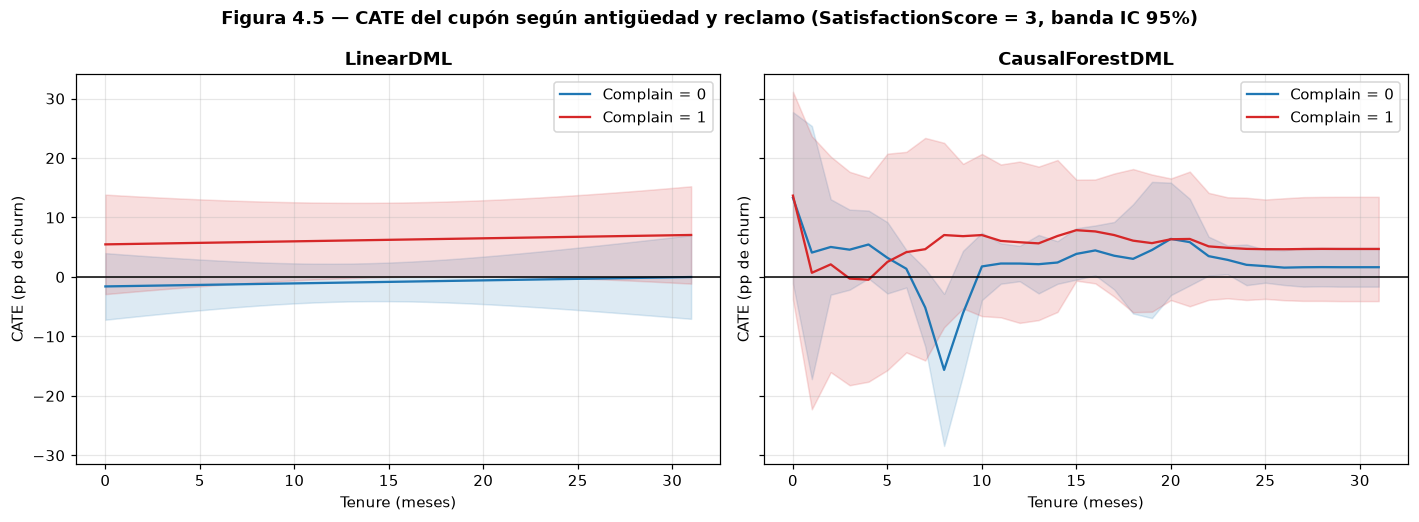

In [12]:
grid = causal.cate_grid(r["dml"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, est_name, label in [(axes[0], "linear_dml", "LinearDML"), (axes[1], "causal_forest", "CausalForestDML")]:
    for complain, color in [(0, "tab:blue"), (1, "tab:red")]:
        g = grid[(grid.Complain == complain) & (grid.SatisfactionScore == 3)]
        ax.plot(g.Tenure, g[f"cate_{est_name}"] * 100, color=color, label=f"Complain = {complain}")
        ax.fill_between(g.Tenure, g[f"ci_inf_{est_name}"] * 100, g[f"ci_sup_{est_name}"] * 100, color=color, alpha=0.15)
    ax.axhline(0, color="k", lw=1)
    ax.set(title=label, xlabel="Tenure (meses)", ylabel="CATE (pp de churn)")
    ax.legend()
fig.suptitle("Figura 4.5 — CATE del cupón según antigüedad y reclamo (SatisfactionScore = 3, banda IC 95%)",
             fontweight="bold")
plt.tight_layout()
plt.show()

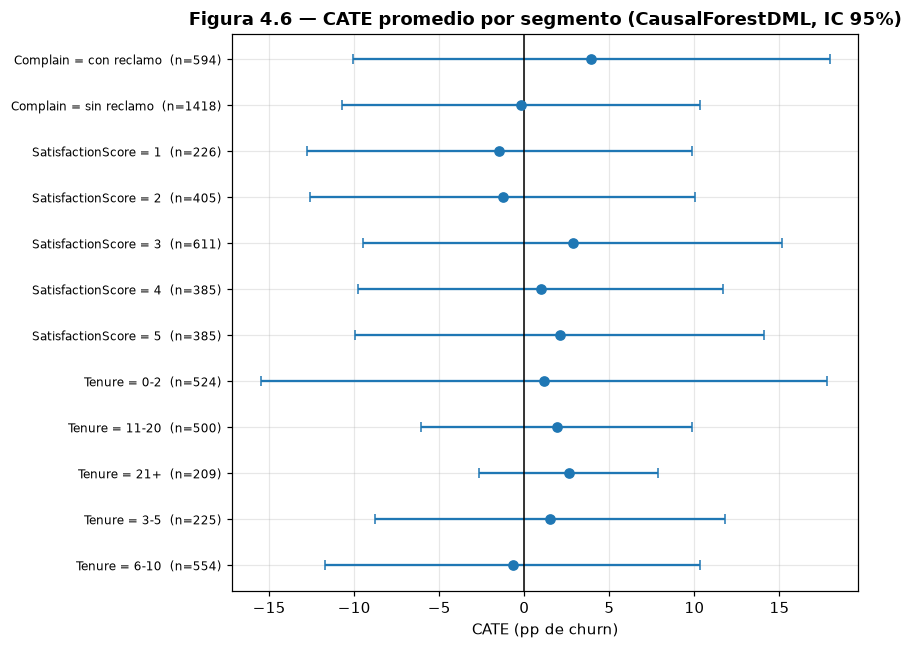

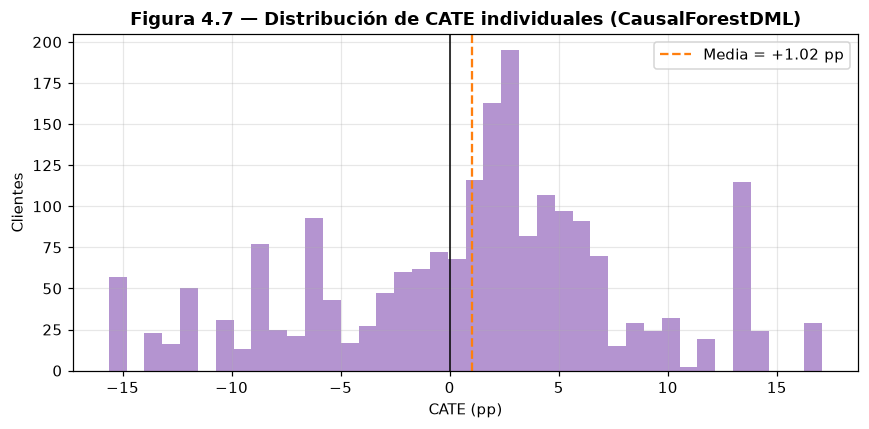

Política 'dar cupón solo si CATE < 0': {'share_cate_negativo': 0.366, 'efecto_medio_dar_a_todos_pp': 1.024, 'efecto_medio_solo_cate_negativo_pp': -6.547, 'churn_evitado_por_100_clientes_targeting': 2.395}


In [13]:
sub = pd.DataFrame(p["cate_subgroups"])
sub["etiqueta"] = sub.variable + " = " + sub.segmento
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(sub))[::-1]
ax.errorbar(sub.cate * 100, yy, xerr=[(sub.cate - sub.ci_inf) * 100, (sub.ci_sup - sub.cate) * 100], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=1)
ax.set_yticks(yy, sub.etiqueta + "  (n=" + sub.n.astype(str) + ")", fontsize=8)
ax.set(title="Figura 4.6 — CATE promedio por segmento (CausalForestDML, IC 95%)", xlabel="CATE (pp de churn)")
plt.tight_layout()
plt.show()

cate = np.asarray(r["dml"]["cate_individual"]) * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cate, bins=40, color="tab:purple", alpha=0.7)
ax.axvline(0, color="k", lw=1)
ax.axvline(cate.mean(), color="tab:orange", ls="--", label=f"Media = {cate.mean():+.2f} pp")
ax.set(title="Figura 4.7 — Distribución de CATE individuales (CausalForestDML)", xlabel="CATE (pp)", ylabel="Clientes")
ax.legend()
plt.tight_layout()
plt.show()
print("Política 'dar cupón solo si CATE < 0':", {k: round(v, 3) for k, v in p["policy"].items()})

**Lectura:** ningún modificador es significativo. El más cercano es `Complain`, con +7,1 pp (p = 0,065): en clientes con reclamo, el cupón no retiene y tiende a asociarse con más churn, consistente con cupones "compensatorios" que no resuelven la causa del reclamo. Todos los IC por segmento incluyen 0. La dispersión de los CATE individuales (Figura 4.7) es en buena parte ruido de estimación: una política de *targeting* basada en esos CATE (36% de clientes con CATE < 0) **no se recomienda** sin validación experimental.

## 4.8 Conclusión de la Fase 4
En la población con soporte común (N = 2.012), **no hay evidencia de que usar cupones reduzca el churn**:
- Regresión backdoor: −1,16 pp (IC 95% [−4,60; +2,28]).
- IPW −1,09 pp, LinearDML +1,11 pp, CausalForestDML +1,42 pp.
- Las 3 refutaciones pasan.

**H-causal-1** (efecto protector menor al ingenuo) y **H-causal-2** (inversión de signo por cupones compensatorios) **no se sostienen**: la confusión observada es débil. La principal amenaza es la confusión no observada, y la forma de resolverla es un **experimento aleatorizado** (A/B) del incentivo, que además elimina el problema de positividad.

# 5. Ensayo crítico — Capacidad predictiva vs palanca causal *(borrador para Carola)*

**1. La variable más predictiva no es una palanca.** En el Random Forest de la Fase 3, `Tenure` es por lejos la variable más importante: permutarla en Test hace caer el ROC-AUC ≈ 0,20 puntos, más de cinco veces lo que cae al permutar la segunda (`Complain`). Pero la antigüedad **no es intervenible**: la empresa no puede "hacer más antiguo" a un cliente. Describe *quién* se va, no *qué hacer* para que se quede. Lo mismo ocurre con `DaySinceLastOrder` (#4 en predicción). En el DAG es un **colisionador y descendiente del churn**, es decir, una consecuencia de que el cliente ya se está yendo. Predice bien precisamente porque es un síntoma, y "reducir los días desde la última compra" no es una política: es el resultado que se quiere lograr. Incluso `Complain` (#2, OR ≈ 7) es una señal de alerta, no una perilla: la palanca es la **causa** del reclamo (logística, calidad), no el reclamo en sí.

**2. Cuándo un gran predictor carece de poder causal.**
- **Confusión:** $X$ y $Y$ comparten una causa común. Por ejemplo, si el engagement no observado (`U_engagement`) aumenta a la vez el uso de la app y la permanencia, `HourSpendOnApp` predice el churn sin ser una palanca.
- **Causalidad inversa:** $Y \to X$. La intención de irse aumenta los días sin comprar.
- **Colisionadores y descendientes de $Y$:** incluirlos mejora la predicción pero sesga cualquier lectura causal. En la simulación de la Fase 4, condicionar en un colisionador **invierte el signo** de un efecto verdadero de +0,10 a −0,46.
- **Proxies:** variables que solo "etiquetan" un segmento.

En todos estos casos $P(Y \mid X)$ es informativa, pero $P(Y \mid do(X))$ puede ser nula o tener el **signo opuesto**.

**3. El caso del cupón.** El cupón aporta ≈ 0 a la predicción (`CouponUsed` #16 por permutación) y su efecto causal estimado es ≈ 0 (−1,2 pp, IC [−4,6; +2,3]). Sin embargo, la *intensidad* de uso se asocia con **más** churn (+1,1 pp por cupón), incluso ajustando por Z. Leer ese coeficiente como causal ("los cupones espantan clientes") sería tan erróneo como la lectura ingenua original ("los clientes con cupones se quedan, entonces los cupones retienen"). La explicación más plausible es la autoselección de clientes sensibles al precio, una variable que no observamos. Además, 808 clientes están en perfiles donde **todos** usaron cupón: para ellos ningún análisis observacional puede decir qué habría pasado sin cupón.

**4. Implicancia de negocio.** *Targeting* por **probabilidad de churn** (predictivo) ≠ *targeting* por **uplift / CATE** (causal). Un cliente con alta probabilidad de irse puede ser un "lost cause" al que el cupón no cambia nada. Uno con baja probabilidad puede ser un "sure thing" que lo usaría igual, y el cupón regalaría margen. Solo los "persuadables" (CATE < 0) justifican el gasto, y los "sleeping dogs" (CATE > 0) empeoran con él.

Recomendación:
- Usar el modelo predictivo calibrado para **detectar** clientes en riesgo y priorizar la atención de reclamos.
- No escalar la política de cupones sobre la base de la correlación observada.
- Validar cualquier incentivo con un **experimento A/B**, que garantiza positividad e ignorabilidad por diseño.
- Con costo de cupón $c$ y valor de retener a un cliente $V$, el cupón conviene solo si $-\tau \cdot V > c$. Aun en el extremo favorable del IC ($\tau = -4{,}6$ pp) se requiere $c < 0{,}046\,V$.